<a href="https://colab.research.google.com/github/Anoshln/LAB-Colab/blob/main/Lab5_%D0%90%D0%BD%D0%BE%D1%88%D0%B8%D0%BD_%D0%A0%D1%83%D0%B4%D1%8C__%D0%A7%D0%B5%D1%87%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа 5 Моделирование движения электрических зарядов в постоянных электрических и магнитных полях

Работу выполнили Аношин Глеб и Рудь Анна.

**Запуск:** выполните все ячейки по порядку сверху вниз (команда «Выполнить все»). Все необходимые функции включены в файл; первая ячейка кода содержит только импорты. Графики и результаты уже сохранены. В последнем вычислительном блоке выполняются десять групп проверок.

ФИО: Аношин Глеб Алексеевич, Рудь Анна Ивановна, Чечко Максим Сергеевич

Группа: 251050

## Подключите необходимые библиотеки для лабораторной работы

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.stats import norm, chi2

## Теория

### Движение заряда в электромагнитном поле
Сила Лоренца: $\mathbf F=q(\mathbf E+\mathbf v\times\mathbf B)$, $d\mathbf p/dt=\mathbf F$.
Для нерелятивистского движения $\mathbf p=m_0\mathbf v$; для релятивистского
$\mathbf p=\gamma m_0\mathbf v$, где $\gamma=(1-|\mathbf v|^2/c^2)^{-1/2}$.
Решаем задачу Коши для координат и скоростей. Магнитная сила перпендикулярна скорости и не совершает работы.

### Моделирование движения электрических зарядов в постоянном магнитном моле

В однородном поле используем $\tau=t/T$, $T=2\pi m_0/(|q|B_0)$, $\mathbf u=\mathbf v/c$, $\mathbf r_* = \mathbf r/(cT)$, $\mathbf H=\mathbf B/B_0$.
Для положительного заряда:
$$\frac{d\mathbf r_*}{d\tau}=\mathbf u,\qquad \frac{d\mathbf u}{d\tau}=2\pi(\mathbf u\times\mathbf H).$$
Компоненты произведения: $(u_yH_z-u_zH_y,\ u_zH_x-u_xH_z,\ u_xH_y-u_yH_x)$.
Порядок состояния в этом разделе: $(x,y,z,u_x,u_y,u_z)$. Все графики показывают безразмерные величины. При $H=(0,0,1)$ период равен 1, радиус $u_\perp/(2\pi)$, шаг винтовой линии $u_z$.

#### Задание. Создайте функцию правой части уравнения 1.43

In [28]:
def LorenzForce(t, z, H=(0., 0., 1.)):
    """Состояние: x, y, z, vx, vy, vz; положительный заряд."""
    return np.r_[z[3:], 2*np.pi*np.cross(z[3:], H)]

#### Задание построить траекторию движения заряда в постоянном магнитном поле с помощью функции LorenzForce()

Для решения ДУ можно использовать решатели дифференциальных уравнений Python [scipy.integrate](https://docs.scipy.org/doc/scipy/reference/integrate.html)

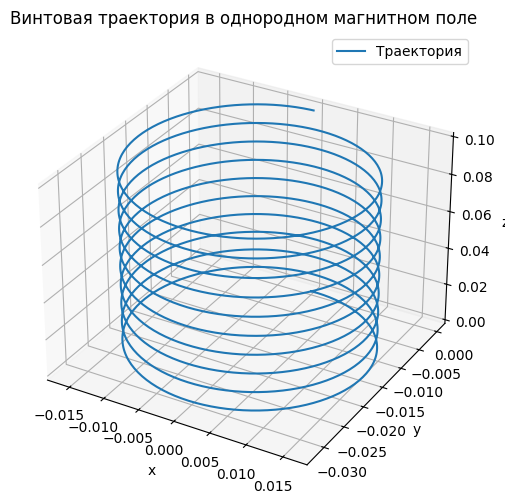

Максимальная ошибка координат: 2.3312871903220084e-10
Максимальное изменение v²: 2.930550142832278e-10


In [29]:
%matplotlib inline
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True})
def chart(ax, x, y, title, xlabel='t', ylabel='Значение', **kwargs):
    ax.plot(x, y, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
def trajectory(r, title):
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot(*r.T, label='Траектория')
    ax.set(title=title, xlabel='x', ylabel='y', zlabel='z')
    ax.legend(); plt.show()
def integrate(fun, initial, times):
    sol = solve_ivp(fun, (times[0], times[-1]), initial, t_eval=times,
                    rtol=1e-9, atol=1e-11, max_step=0.02)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y.T

H = np.array([0., 0., 1.])
t = np.linspace(0, 10, 2049)
Rmag = integrate(lambda t,s: LorenzForce(t,s,H), [0, 0, 0, .1, 0, .01], t)
trajectory(Rmag[:, :3], 'Винтовая траектория в однородном магнитном поле')
exact = np.column_stack((.1*np.sin(2*np.pi*t)/(2*np.pi),
                        .1*(np.cos(2*np.pi*t)-1)/(2*np.pi), .01*t))
print('Максимальная ошибка координат:', np.max(np.abs(Rmag[:, :3]-exact)))
print('Максимальное изменение v²:', np.ptp(np.sum(Rmag[:, 3:]**2, axis=1)))

#### Задание. Постройте проекции траектории движения на соответствующие координатные плоскости

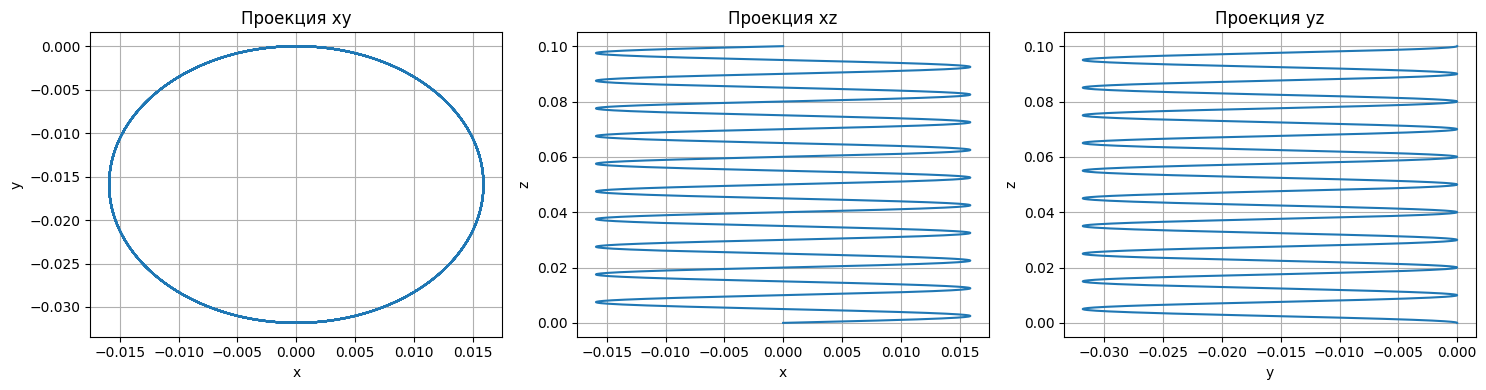

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (i,j) in zip(axes, [(0,1),(0,2),(1,2)]):
    chart(ax, Rmag[:,i], Rmag[:,j], 'Проекция '+ 'xyz'[i]+'xyz'[j], 'xyz'[i], 'xyz'[j])
plt.tight_layout(); plt.show()

### Постоянные скрещённые электрическое и магнитное поля
Положим $\mathbf e=\mathbf E/(cB_0)$, сохранив единицы предыдущего раздела.
Классическая модель: $\dot{\mathbf u}=\mathbf f$, где
$$\mathbf f=2\pi(\mathbf e+\mathbf u\times\mathbf H).$$
Релятивистская модель (1.65):
$$\dot{\mathbf u}=[\mathbf f-\mathbf u(\mathbf f\cdot\mathbf u)]\sqrt{1-|\mathbf u|^2},\qquad \dot{\mathbf r}_*=\mathbf u.$$
В частности, при $\mathbf H=(0,0,1)$ и $\mathbf e=(0,e_y,0)$ классические ускорения равны $2\pi(u_y,e_y-u_x,0)$.
В исходном тексте были перепутаны индексы компонент; здесь приведена исправленная векторная запись.

#### Задание. Сравнить классическое и релятивистское движение в скрещённых полях
Начальные скорости и координаты равны нулю. В условии дважды упоминается одна и та же система (1.65); это трактуется как сравнение релятивистской и нерелятивистской моделей. Исследовать, при каких скоростях различия становятся заметными.

Ey=0.01, Классическая: max(v/c)=0.02000
Ey=0.01, Релятивистская: max(v/c)=0.02000
Ey=0.1, Классическая: max(v/c)=0.20000
Ey=0.1, Релятивистская: max(v/c)=0.19802
Ey=0.4, Классическая: max(v/c)=0.80000
Ey=0.4, Релятивистская: max(v/c)=0.68965


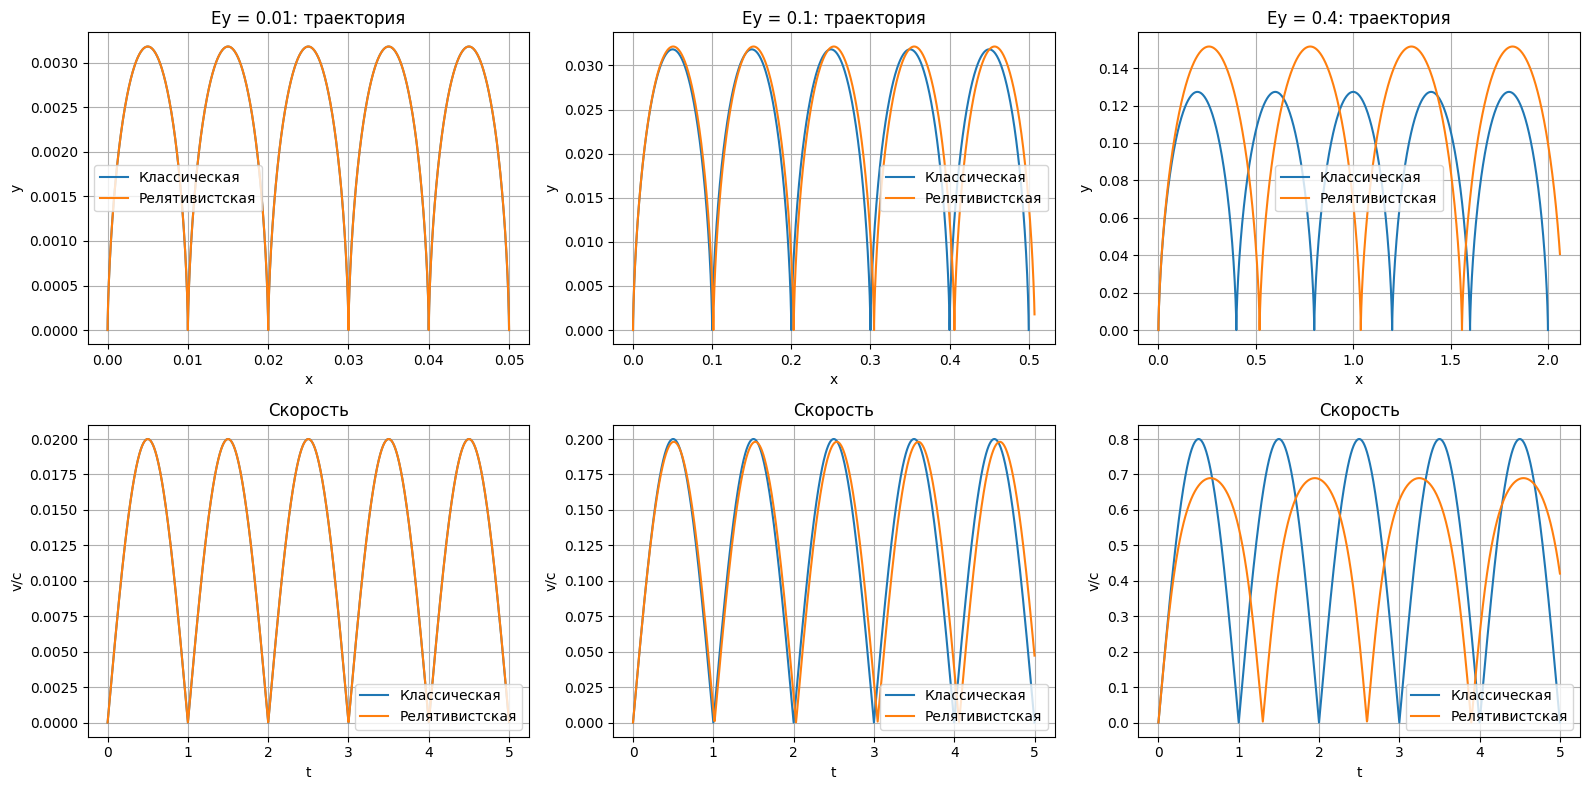

γ−1 — поправка к фактору Лорена.
v/c=0.1: γ−1=0.50%
v/c=0.2: γ−1=2.06%
v/c=0.3: γ−1=4.83%
v/c=0.5: γ−1=15.47%
v/c=0.8: γ−1=66.67%


In [31]:
def em_rhs(E, relativistic=False):
    def rhs(t, s):
        v = s[3:]
        force = 2*np.pi*(E+np.cross(v, [0,0,1]))
        acceleration = force
        if relativistic:
            acceleration = (force-v*np.dot(force,v))*np.sqrt(max(0.,1-np.dot(v,v)))
        return np.r_[v, acceleration]
    return rhs
em_results = {}
te = np.linspace(0, 5, 1501)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for col, e in enumerate([.01, .1, .4]):
    E = np.array([0.,e,0.])
    for rel, label in [(False,'Классическая'), (True,'Релятивистская')]:
        s = integrate(em_rhs(E, rel), np.zeros(6), te)
        em_results[(e,rel)] = s.copy()
        chart(axes[0,col], s[:,0], s[:,1], f'Ey = {e}: траектория', 'x','y', label=label)
        chart(axes[1,col], te, np.linalg.norm(s[:,3:],axis=1), 'Скорость', 't','v/c', label=label)
        print(f'Ey={e}, {label}: max(v/c)={np.linalg.norm(s[:,3:],axis=1).max():.5f}')
    axes[0,col].legend(); axes[1,col].legend()
plt.tight_layout(); plt.show()
print('γ−1 — поправка к фактору Лорена.')
for beta in [.1,.2,.3,.5,.8]:
    print(f'v/c={beta:.1f}: γ−1={(1/np.sqrt(1-beta**2)-1)*100:.2f}%')

### Неоднородное магнитное поле диполя
В этом разделе используются отдельные безразмерные единицы: длина $R_0$, время $T_0$, скорость $R_0/T_0$.
$$\dot{\mathbf r}=\mathbf v,\qquad \dot{\mathbf v}=2\pi(\mathbf v\times\mathbf H(\mathbf r)),$$
$$\mathbf H(\mathbf r)=\frac{3(\mathbf m\cdot\mathbf r)\mathbf r}{|\mathbf r|^5}-\frac{\mathbf m}{|\mathbf r|^3},\quad
\mathbf m=(0,\sin 11.5^\circ,\cos 11.5^\circ).$$
Поле и его амплитуда заданы непосредственно этой безразмерной моделью; дополнительная нормировка поля вдоль траектории не применяется. Значение скорости 1.55 здесь не означает 1.55c.
Диагностики: $K=v^2/2$, $\mu=v_\perp^2/(2|H|)$,
$\rho_L=v_\perp/(2\pi|H|)$, $\varepsilon=\rho_L|\nabla|H||/|H|$.
$K$ — точный инвариант, а $\mu$ — приближённый при малой неоднородности на масштабе ларморовского радиуса. Поле сингулярно в начале координат; выбранные траектории не должны проходить через эту точку.
Порядок состояния для совместимости с шаблоном: $(x,v_x,y,v_y,z,v_z)$.

#### Задание. Написать функцию решения уравнения (1.76)

In [32]:
DIPOLE_MOMENT = np.array([0, np.sin(np.deg2rad(11.5)), np.cos(np.deg2rad(11.5))])
def field(r):
    r = np.asarray(r, dtype=float)
    radius = np.linalg.norm(r, axis=-1, keepdims=True)
    if np.any(radius == 0):
        raise ValueError("Поле диполя не определено в начале координат")
    return 3*np.sum(r*DIPOLE_MOMENT,axis=-1,keepdims=True)*r/radius**5-DIPOLE_MOMENT/radius**3
def f(state, t):
    r, v = state[::2], state[1::2]
    z = np.empty(6)
    z[::2] = v
    z[1::2] = 2*np.pi*np.cross(v, field(r))
    return z

In [33]:
Tmax, Ts = 20., .01

#### Задание. Смоделировать движение заряженной частицы в магнитном поле диполя
Постройте:
1. Траекторию движения заряда
2. Зависимость разности между начальным и текущими значениями кинетической энергии заряда от времени;
3. Зависимость магнитного момента заряда от времени;
4. Зависимость коэффициента неоднородности поля от времени;
5. Разность модулей радиусов-векторов зарядов, находившихся в начальный момент времени в близких точках.
1. Зависимость модуля радиуса-вектора от времени;
7. Зависимость скорости изменения модуля радиуса-вектора от времени; 3) спектр зависимости модуля радиуса-вектора от времени;
8. Зависимость разности между начальным и текущими значениями кинетической энергии заряда от времени;
9. Зависимость магнитного момента заряда от времени;
10. Зависимость коэффициента неоднородности поля от времени;
11. Разность модулей радиусов-векторов зарядов, находившихся в начальный момент времени в близких точках.

In [34]:
V0 = 1.55
state0 = [1., 0., 0., V0, 0., 0.]
t = np.arange(0, Tmax+Ts/2, Ts)
states = integrate(lambda t,s: f(s,t), state0, t)
x, y, z = states[:,0], states[:,2], states[:,4]

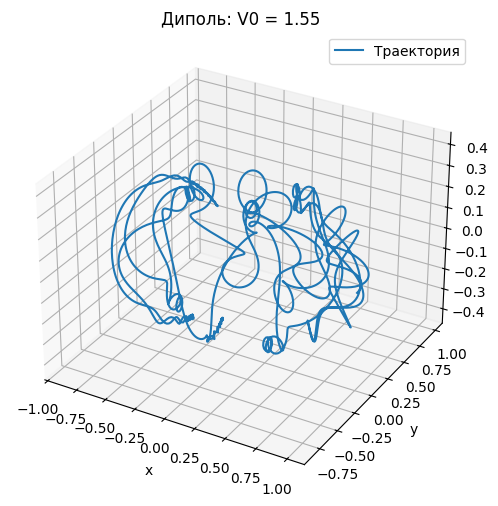

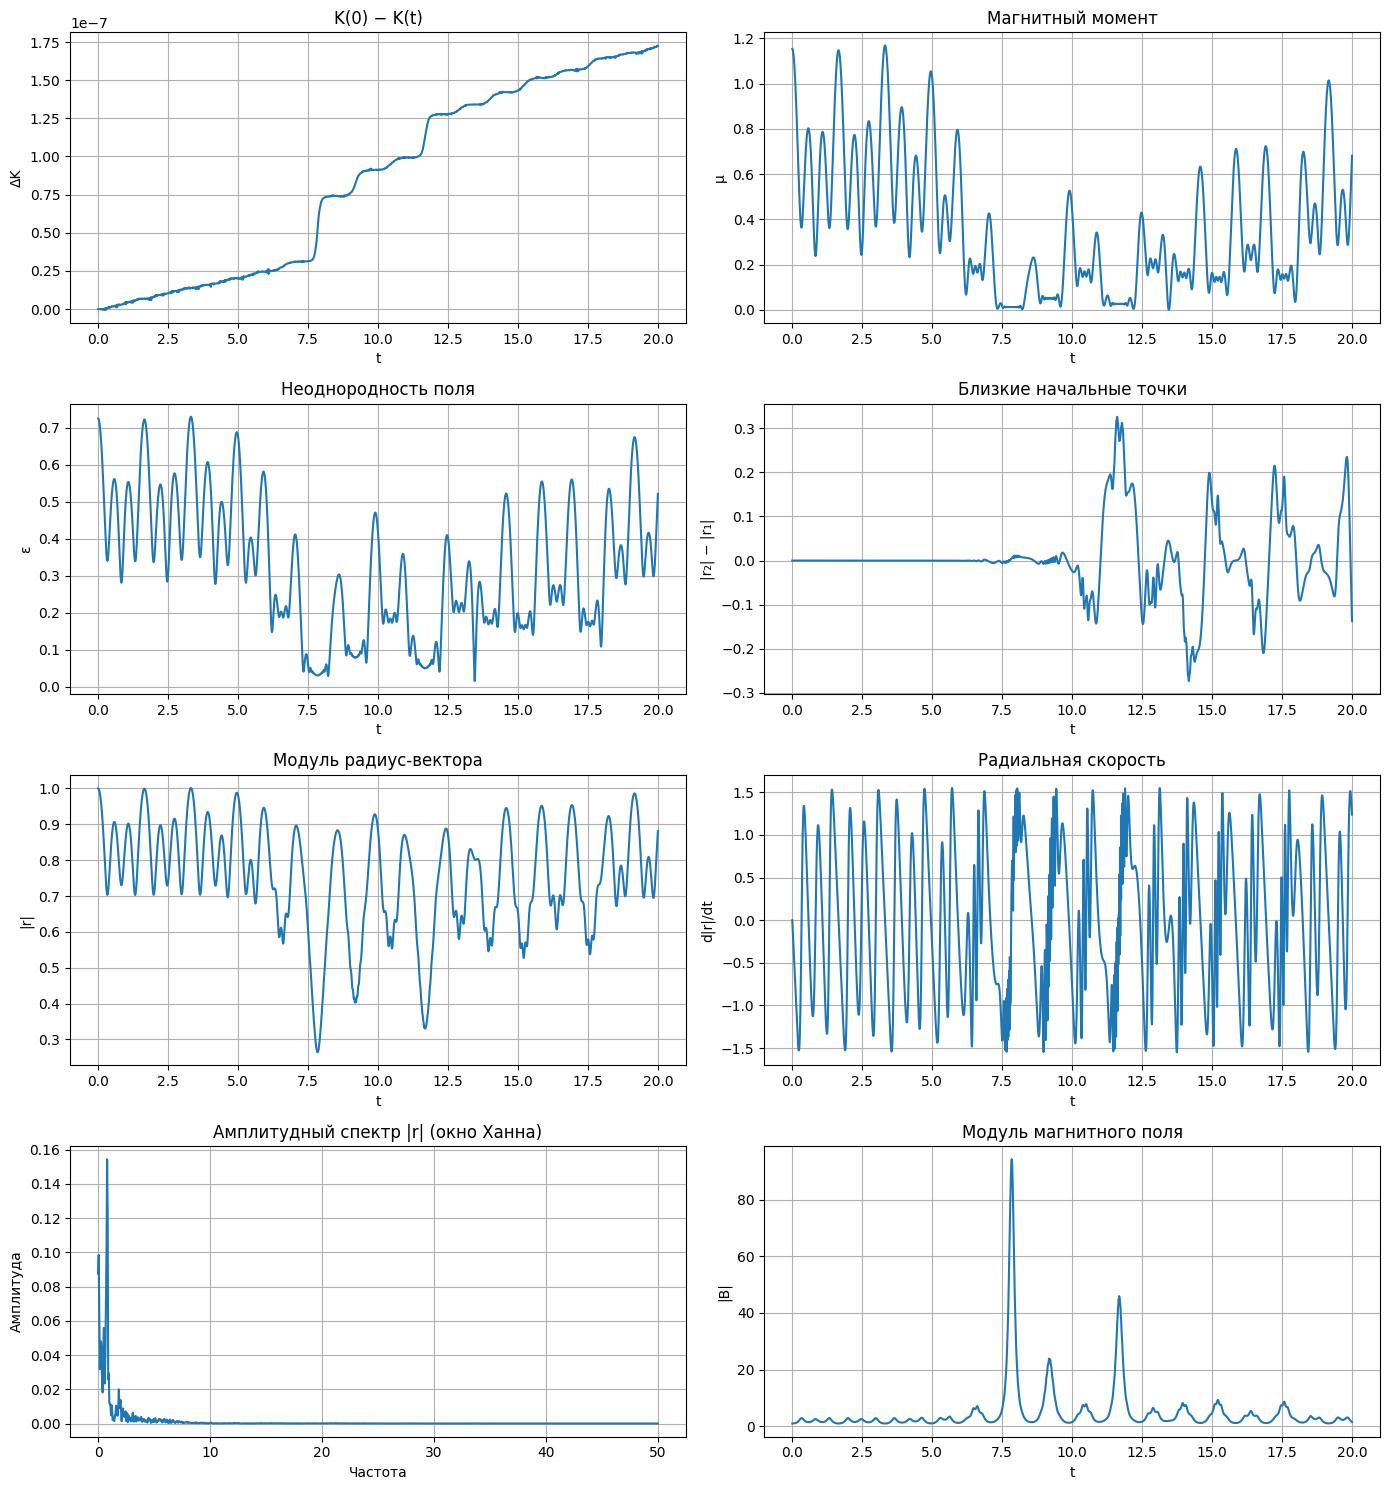

Относительная погрешность энергии: 1.4375442845585314e-07
Диапазон ε: 0.015251620291577927 0.7301086500839168
Диапазон μ: 0.0006367317399760682 1.1679105821340536


In [35]:
def dipole_diagnostics(states, times, initial, title):
    r, v = states[:,::2], states[:,1::2]
    B = field(r); b = np.linalg.norm(B,axis=1)
    speed2 = np.sum(v*v,axis=1)
    parallel = np.sum(v*B,axis=1)/b
    perpendicular2 = np.maximum(0,speed2-parallel**2)
    mu = perpendicular2/(2*b)
    radius = np.linalg.norm(r,axis=1)
    radial_speed = np.sum(r*v,axis=1)/radius
    # ε = ρL |grad |B|| / |B|; ρL = v_perp/(2π|B|).
    h = 1e-5
    grad = np.column_stack([(np.linalg.norm(field(r+np.eye(3)[j]*h),axis=1)-
                            np.linalg.norm(field(r-np.eye(3)[j]*h),axis=1))/(2*h) for j in range(3)])
    epsilon = np.sqrt(perpendicular2)*np.linalg.norm(grad,axis=1)/(2*np.pi*b*b)
    nearby = np.array(initial, dtype=float); nearby[0] += 1e-5
    other = integrate(lambda t,s:f(s,t), nearby, times)
    difference = np.linalg.norm(other[:,::2],axis=1)-radius
    trajectory(r, title)
    window = np.hanning(len(times)); signal=(radius-radius.mean())*window
    spectrum = 2*np.abs(np.fft.rfft(signal))/window.sum()
    freq = np.fft.rfftfreq(len(times),times[1]-times[0])
    fig, axes = plt.subplots(4,2,figsize=(14,15))
    series = [(times,(speed2[0]-speed2)/2,'K(0) − K(t)','t','ΔK'),
              (times,mu,'Магнитный момент','t','μ'),
              (times,epsilon,'Неоднородность поля','t','ε'),
              (times,difference,'Близкие начальные точки','t','|r₂| − |r₁|'),
              (times,radius,'Модуль радиус-вектора','t','|r|'),
              (times,radial_speed,'Радиальная скорость','t','d|r|/dt'),
              (freq,spectrum,'Амплитудный спектр |r| (окно Ханна)','Частота','Амплитуда'),
              (times,b,'Модуль магнитного поля','t','|B|')]
    for ax,(xx,yy,title,xl,yl) in zip(axes.flat,series): chart(ax,xx,yy,title,xl,yl)
    plt.tight_layout(); plt.show()
    print('Относительная погрешность энергии:', np.max(np.abs(speed2-speed2[0]))/speed2[0])
    print('Диапазон ε:', epsilon.min(), epsilon.max())
    print('Диапазон μ:', mu.min(), mu.max())
dipole_diagnostics(states,t,state0,'Диполь: V0 = 1.55')

#### Задание. Измените параметры моделирования, посмотрите, что получится при построение зависимостей из прошлого задания


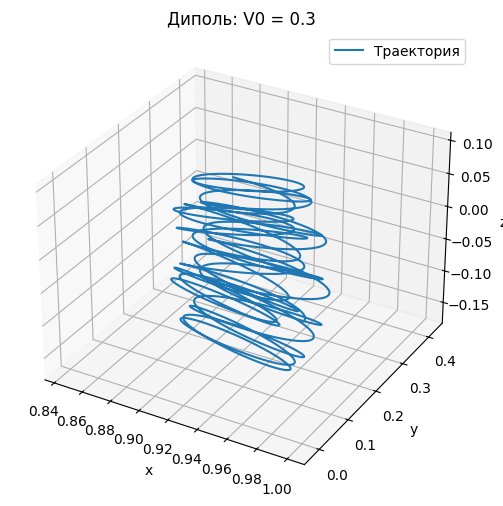

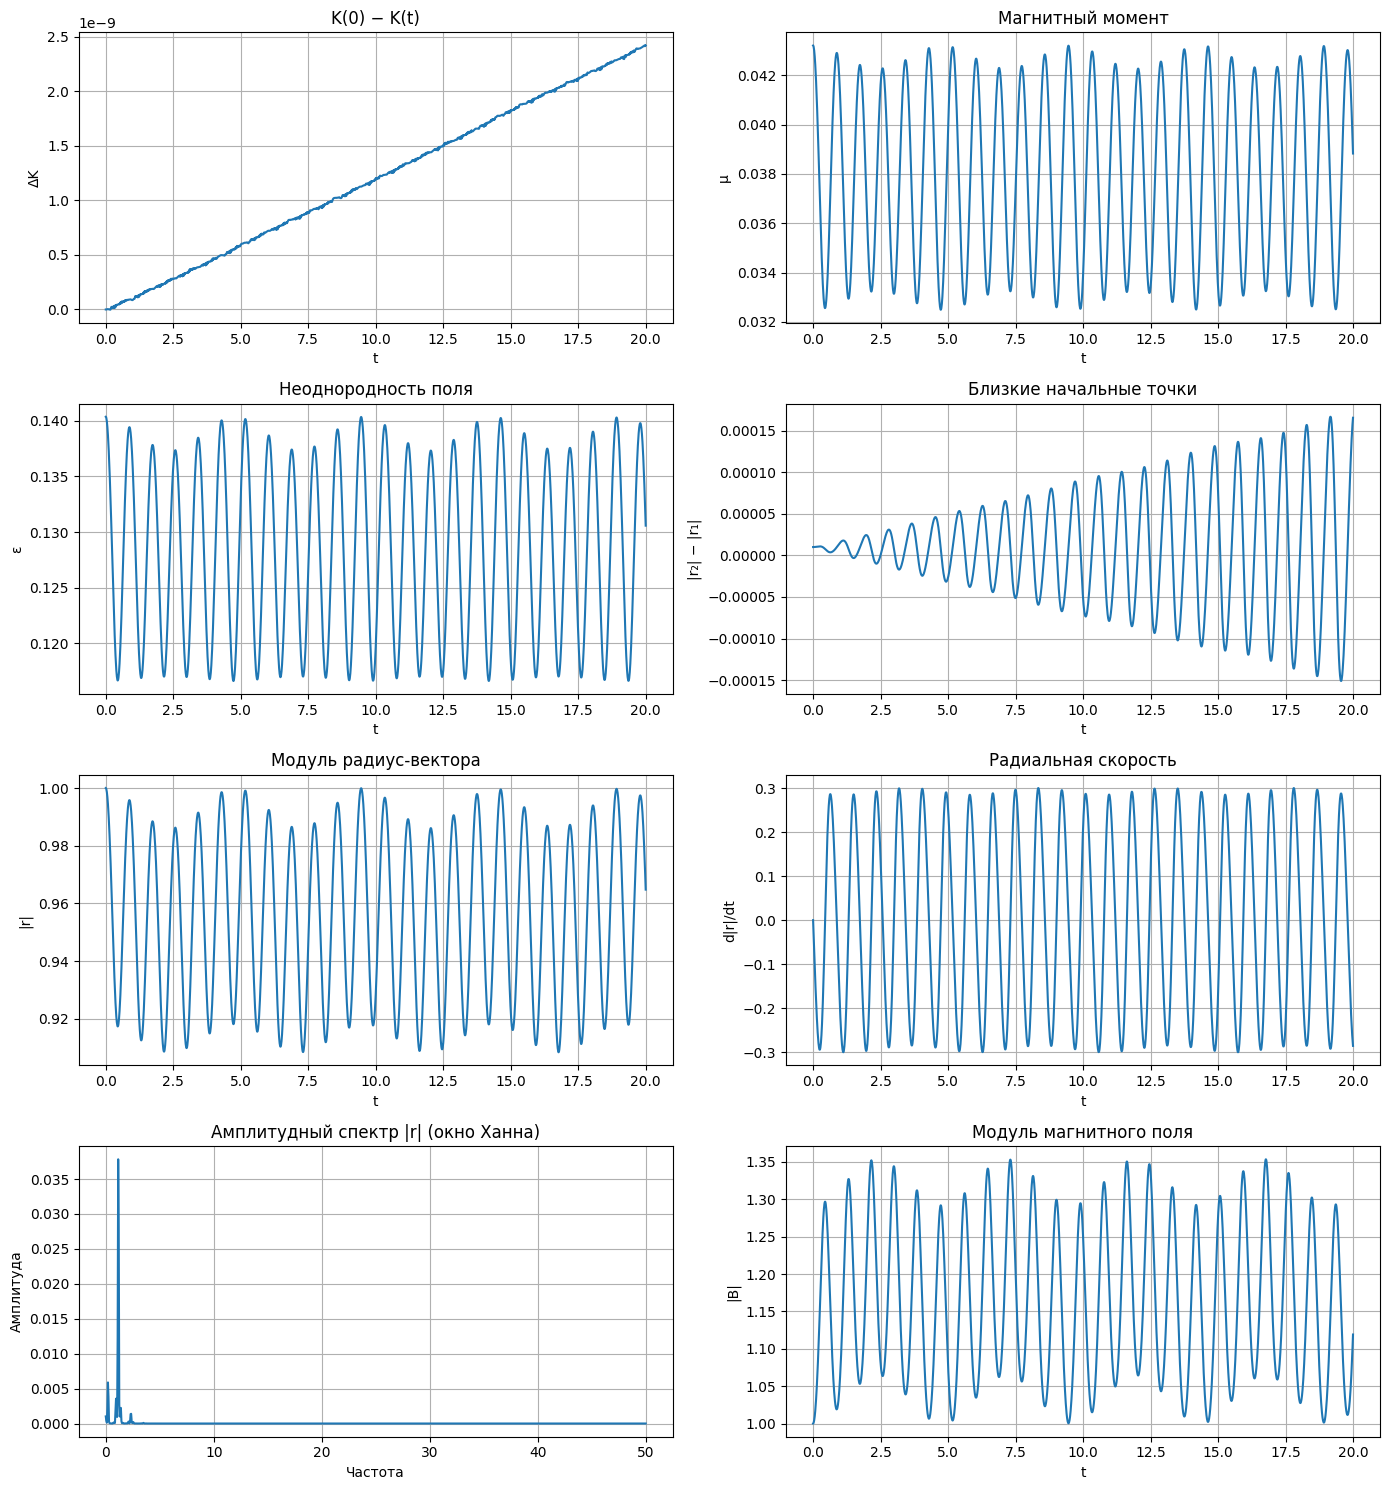

Относительная погрешность энергии: 5.3808543423430585e-08
Диапазон ε: 0.11662305248017593 0.14036387458533436
Диапазон μ: 0.03248947225256538 0.043211359202679905


In [36]:
# Повторяем все зависимости при меньшей начальной скорости.
state_low = [1.,0.,0.,.3,0.,0.]
states_low = integrate(lambda t,s:f(s,t), state_low,t)
dipole_diagnostics(states_low,t,state_low,'Диполь: V0 = 0.3')

### Вывод

В однородном магнитном поле получена винтовая траектория: поперечное движение периодическое, продольное равномерное, энергия сохраняется. Аналитическое решение используется для проверки численного расчёта.

В скрещённых полях возникает дрейф вдоль E×B. Релятивистская поправка к γ составляет около 2% при 0.2c и 4.8% при 0.3c; единого порога нет, он зависит от требуемой точности и времени наблюдения.

В дипольном поле энергия остаётся постоянной с численной погрешностью. Магнитный момент является лишь приближённым инвариантом при ε ≪ 1. Снижение скорости уменьшает ларморовский радиус и улучшает применимость адиабатического приближения. Разность радиусов близких траекторий сама по себе не доказывает хаос.

**Уточнения к исходной теории:** использовано векторное произведение v×B с правильными компонентами; производные координат равны соответствующим компонентам скорости; электрическая сила содержит Ex, Ey, Ez соответственно. Магнитный момент вычисляется через поперечную скорость. Заряд принят положительным. Не заданные в условии поля и интервал времени явно указаны в коде.

### Случайные блуждания

Впервые задача о случайных блужданиях была сформулирована в 1906 г. Пирсоном. В
первоначальной формулировке требовалось определить, на каком расстоянии от
начальной точки будет находиться пешеход, сделав N шагов равной длины в
произвольных направлениях. Отметим, что со времени постановки задачи в такой
формулировке модели случайного блуждания получили широкое распространение в
физике, биологии, химии, общественных науках. Например, для описания диффузии
молекул газа, движения коллоидных взвесей в жидкости, моделирования длинных
полимерных цепочек, решения ряда задач квантовой механики и др. В этой и
последующих главах рассматриваются модели, для реализации которых используется
метод случайных блужданий.

Рассмотрим идеализированную одномерную задачу о движении пешехода, который в
момент времени $t = 0$ находится в точке $x = 0$.

Будем считать, что все шаги имеют одинаковую длину $l$, а направление каждого
следующего шага не зависит от направления предыдущего шага. Предположим, что на
каждом шаге по времени пешеход делает шаг вправо с вероятностью p или шаг влево
с вероятностью $q = 1 − p$. Обозначим общее количество шагов, сделанных
пешеходом, вправо $n+$, влево $n−$, тогда полное число шагов равно N = n+ +n−.
Полное смещение пешехода после N шагов равно $x = (n+ −n−)l$, где $−Nl ≤ x ≤
Nl$. Зависимость $x_i$ , $i = 0, 1, . . . , N$, называют реализацией случайного
процесса. Совокупность зависимостей xi , имеющих одинаковую длину и начинающихся
из одной точки, называют ансамблем реализаций. Необходимо определить вероятность
$P_N(x)$ того, что после $N$ шагов пешеход окажется на расстоянии $x$ от начала
отсчета. Знание вероятности позволяет вычислить среднее смещение $⟨x_N⟩$.

В методе полного перебора количество и вероятность всех блужданий для заданных
$N$ и $x$ вычисляются в явном виде.

В методе Монте-Карло в отличие от метода полного перебора всех N-шаговых
блужданий проводится генерация достаточно большого количества реализаций
(ансамбля реализаций) ($NTrial$ — число реализаций в ансамбле) с искомым законом
распределения. При этом длина отдельных реализаций NStep должна быть такой,
чтобы обеспечить принадлежность каждой реализации выбранных блужданий множеству,
содержащему все допустимые блуждания. (Обычно длина реализации варьируется от
100 до 1000 шагов.) Затем из каждой реализации выбираются значения смещения
пешехода на последнем шаге. Это позволяет сформировать выборку длиной $NTrial$,
статистические свойства которой оказываются близкими к свойствам
последовательности, получаемой методом прямого перебора.

#### Задание. Реализовать функцию метода Монте-Карло

In [37]:
# Генератор случайных чисел для воспроизводимых результатов.
rng = np.random.default_rng(251050)

def Walk(NStep=1000, NTrial=1000, p=.5):
    if not 0 <= p <= 1: raise ValueError('p должно лежать в [0,1]')
    return np.where(rng.random((NTrial, NStep)) < p, 1, -1).sum(axis=1)

#### Задание. Реализовать отображение случайной последовательности, полученной методом Монте-Карло. Построить последовательность и гистограмму

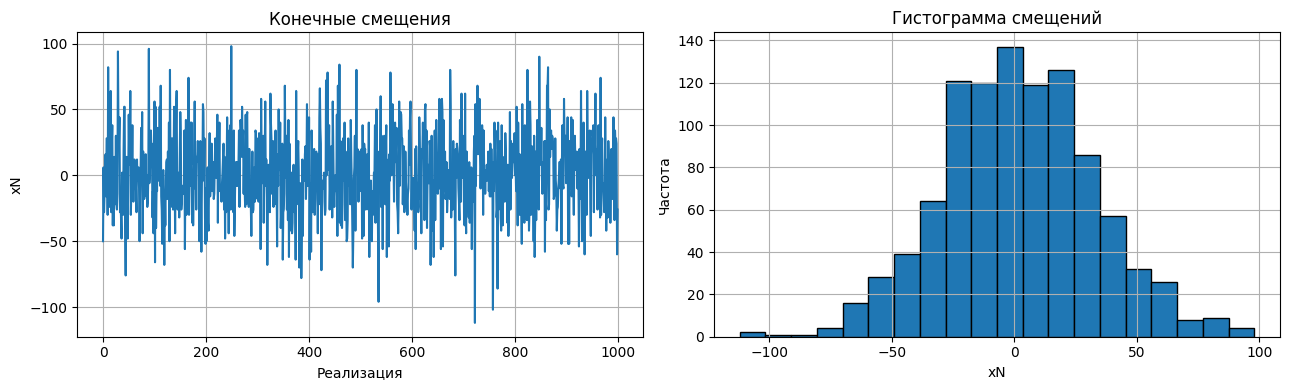

In [38]:
NStep, NTrial, p = 1000, 1000, .5
Mwalk = Walk(NStep,NTrial,p)
fig, axes = plt.subplots(1,2,figsize=(13,4))
chart(axes[0],np.arange(NTrial),Mwalk,'Конечные смещения','Реализация','xN')
axes[1].hist(Mwalk,bins=20,edgecolor='black')
axes[1].set(title='Гистограмма смещений',xlabel='xN',ylabel='Частота')
plt.tight_layout(); plt.show()

Проверяем нормальное приближение распределения конечных смещений.
1. Оценим среднее и СКО по выборке.
2. Вычислим наблюдаемые и ожидаемые частоты в интервалах, включая оба бесконечных хвоста:
$$E_i=N_{Trial}[\Phi((b_{i+1}-\bar x)/s)-\Phi((b_i-\bar x)/s)].$$
3. Рассчитаем $\chi^2=\sum_i(O_i-E_i)^2/E_i$. Ожидаемые частоты должны быть не меньше 5.
4. Поскольку два параметра оценены по выборке, используем $k-1-2$ степеней свободы и уровень значимости 0.005.
Это приближённая проверка: реальное распределение дискретно. Границы интервалов заданы заранее между допустимыми точками решётки.

#### Задание. Реализовать описанный выше алгоритм и вывести значение $\chi^2$

In [39]:
mean, sigma = Mwalk.mean(), Mwalk.std(ddof=0)
print(f'Среднее: {mean:.4f}; СКО: {sigma:.4f}')
print('Теория:', NStep*(2*p-1), np.sqrt(4*NStep*p*(1-p)))
# Границы между доступными точками решётки (шаг 2), хвосты включены.
edges = np.r_[-np.inf, np.arange(-69, 72, 10), np.inf]
observed,_ = np.histogram(Mwalk,edges)
expected = NTrial*np.diff(norm.cdf(edges,mean,sigma))
assert expected.min() >= 5
stat = np.sum((observed-expected)**2/expected)
df = len(observed)-1-2  # нормировка и два оценённых параметра
critical = chi2.ppf(.995,df)
pvalue = chi2.sf(stat,df)
print(f'χ²={stat:.4f}; df={df}; порог={critical:.4f}; p-value={pvalue:.4f}')
print('Гипотеза не отвергается' if stat<critical else 'Гипотеза отвергается')
print('Уровень значимости 0.005; проверяется нормальное приближение дискретного закона.')

Среднее: 1.3860; СКО: 31.2124
Теория: 0.0 31.622776601683793
χ²=5.3554; df=13; порог=29.8195; p-value=0.9665
Гипотеза не отвергается
Уровень значимости 0.005; проверяется нормальное приближение дискретного закона.


Вывод критерия рассчитан выше для фактической выборки, а не перенесён из примера. При оценке среднего и СКО число степеней свободы равно k−1−2. В исходнике ошибочно вычитаются три параметра. Нормальная плотность имеет множитель 1/(σ√(2π)). Неотвержение гипотезы не доказывает точную нормальность: конечное смещение имеет дискретный биномиальный закон.

#### Задание. Реализовать функцию построения функции распределения. Функция возвращает значения вероятности нахождения пешехода в данной точке.

In [40]:
def DistrR(M):
    """Возвращает точки и эмпирические вероятности (массу, не плотность)."""
    values, counts = np.unique(M,return_counts=True)
    return values, counts/len(M)

#### Задание. Применить полученную функцию для получения функции распределения

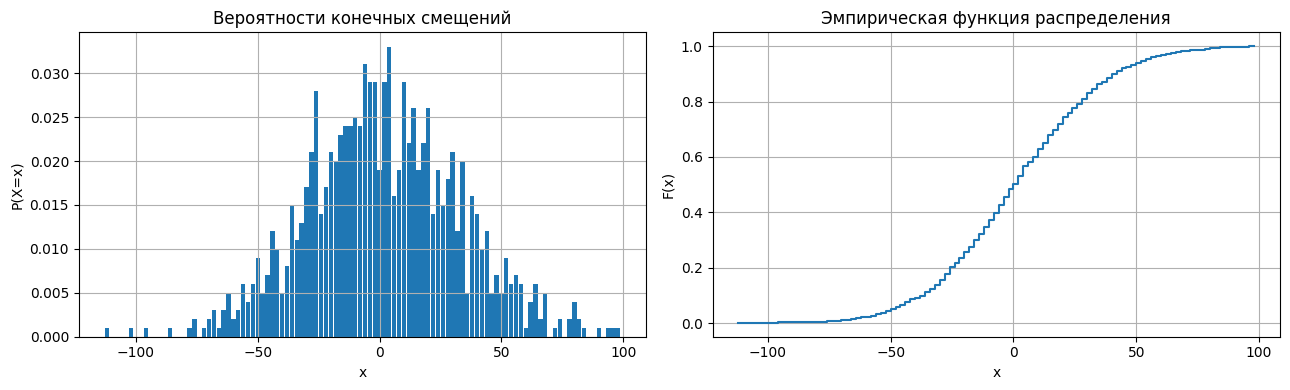

In [41]:
values, probabilities = DistrR(Mwalk)
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].bar(values,probabilities,width=1.8)
axes[0].set(title='Вероятности конечных смещений',xlabel='x',ylabel='P(X=x)')
axes[1].step(values,np.cumsum(probabilities),where='post')
axes[1].set(title='Эмпирическая функция распределения',xlabel='x',ylabel='F(x)')
plt.tight_layout(); plt.show()

### Метод случайных блужданий на плоскости

Рассмотрим обобщения метода одномерных случайных блужданий для систем большей
размерности. Их обсуждение совершенно естественно начать с рассмотрения
случайных блужданий в двумерной плоскости. Статический характер задачи
случайного блуждания означает, что следует рассматривать либо большое количество
случайных блужданий одного пешехода, либо большое число пешеходов, движущихся
одновременно. Далее нами используется второй подход.

Рассмотрим группу пешеходов, расположенных в момент времени $t = 0$, случайным образом в круге единичного радиуса с центром в начале координат. Будем считать, что на каждом шаге по времени каждый пешеход движется случайным образом
равновероятно в одном из четырех направлений: в положительном направлении оси
OX, в отрицательном направлении оси OX, в положительном направлении оси OY, в
отрицательном направлении оси OY. При этом направление движения выбирается в
соответствии с методом Монте-Карло в зависимости от величины случайного числа и
заданного порогового значения.

#### Задание. Создать функцию возвращающую начальную конфигурацию системы

In [42]:
def Init2(NParticle,R):
    phi = rng.uniform(0,2*np.pi,NParticle)
    radius = R*np.sqrt(rng.random(NParticle))
    return np.column_stack((radius*np.cos(phi),radius*np.sin(phi)))

#### Задание. Создать функцию возвращающую мгновенные значения координат пешеходов

In [43]:
def Move(A,NParticle,NStep):
    directions = np.array([[1,0],[-1,0],[0,1],[0,-1]])
    Z = np.empty((NStep+1,NParticle,2))
    Z[0] = A
    Z[1:] = A+np.cumsum(directions[rng.integers(0,4,(NStep,NParticle))],axis=0)
    return Z

#### Задание. Применить функции

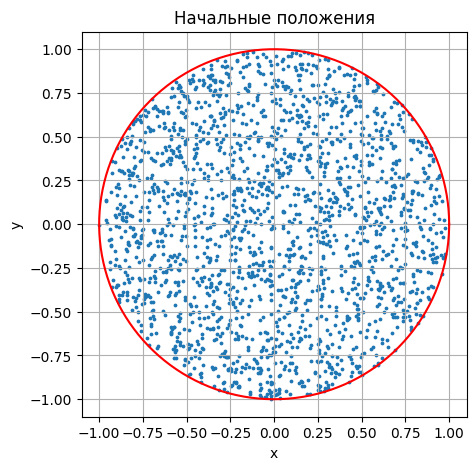

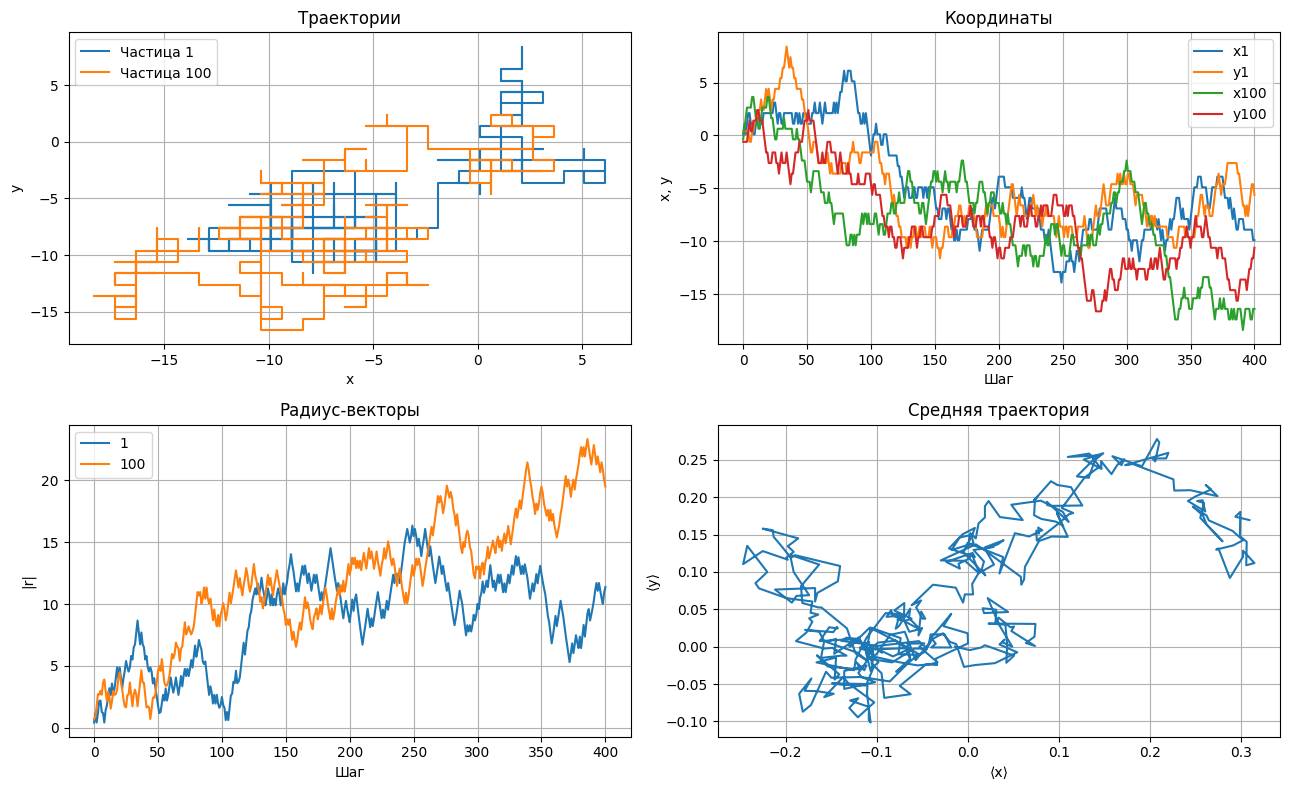

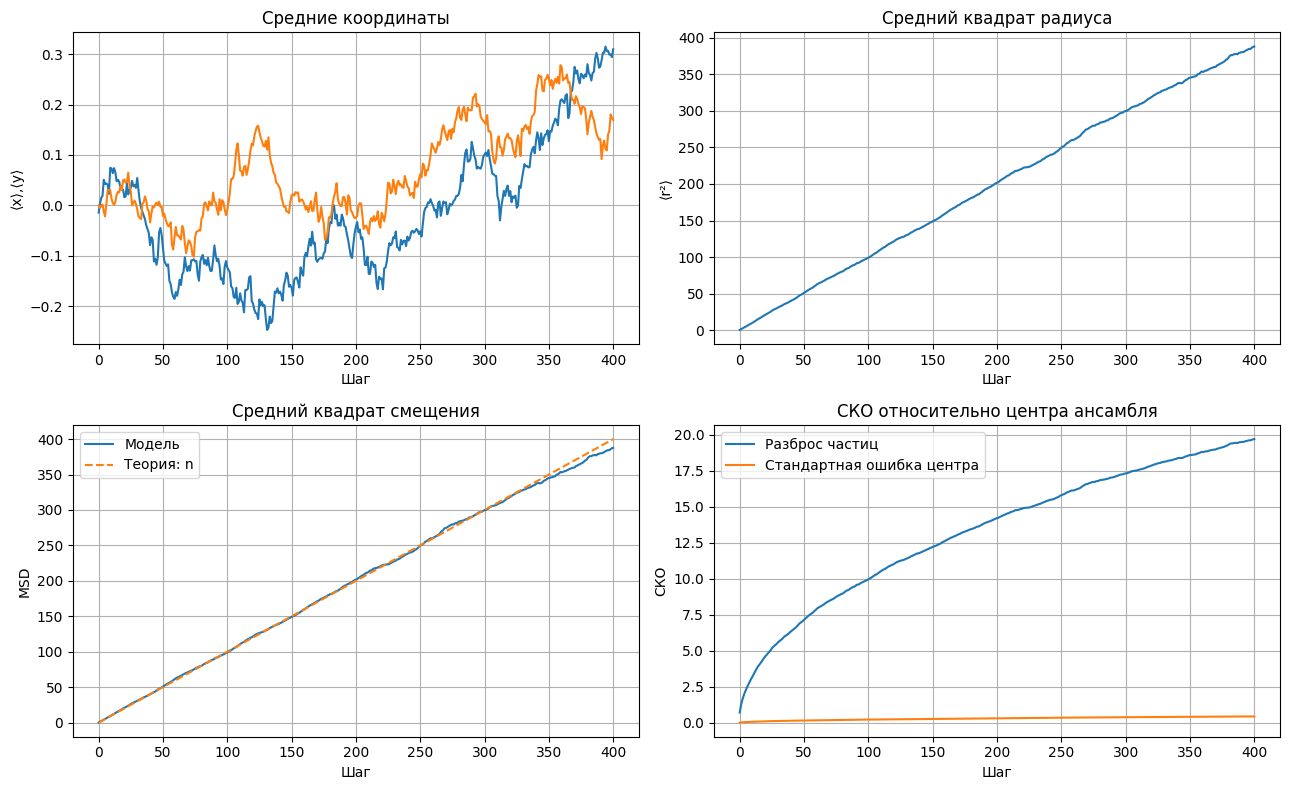

In [44]:
NParticle, NStep, R = 2000, 400, 1
A=Init2(NParticle,R); Am=Move(A,NParticle,NStep)
steps=np.arange(NStep+1)
fig,ax=plt.subplots(); ax.scatter(*A.T,s=3)
phi=np.linspace(0,2*np.pi,300); ax.plot(np.cos(phi),np.sin(phi),'r')
ax.set(title='Начальные положения',xlabel='x',ylabel='y',aspect='equal'); plt.show()
fig,axes=plt.subplots(2,2,figsize=(13,8))
for idx in [0,99]:
    chart(axes[0,0],Am[:,idx,0],Am[:,idx,1],'Траектории','x','y',label=f'Частица {idx+1}')
    chart(axes[0,1],steps,Am[:,idx,0],'Координаты','Шаг','x, y',label=f'x{idx+1}')
    axes[0,1].plot(steps,Am[:,idx,1],label=f'y{idx+1}')
    chart(axes[1,0],steps,np.linalg.norm(Am[:,idx],axis=1),'Радиус-векторы','Шаг','|r|',label=str(idx+1))
center=Am.mean(axis=1)
chart(axes[1,1],center[:,0],center[:,1],'Средняя траектория','⟨x⟩','⟨y⟩')
for ax in axes.flat:
    if ax.get_legend_handles_labels()[0]: ax.legend()
plt.tight_layout(); plt.show()
disp=Am-A
msd=np.mean(np.sum(disp**2,axis=2),axis=1)
spread=np.sqrt(np.mean(np.sum((Am-center[:,None,:])**2,axis=2),axis=1))
fig,axes=plt.subplots(2,2,figsize=(13,8))
chart(axes[0,0],steps,center,'Средние координаты','Шаг','⟨x⟩,⟨y⟩')
chart(axes[0,1],steps,np.mean(np.sum(Am**2,axis=2),axis=1),'Средний квадрат радиуса','Шаг','⟨r²⟩')
chart(axes[1,0],steps,msd,'Средний квадрат смещения','Шаг','MSD',label='Модель')
axes[1,0].plot(steps,steps,'--',label='Теория: n'); axes[1,0].legend()
chart(axes[1,1],steps,spread,'СКО относительно центра ансамбля','Шаг','СКО',label='Разброс частиц')
axes[1,1].plot(steps,spread/np.sqrt(NParticle),label='Стандартная ошибка центра'); axes[1,1].legend()
plt.tight_layout(); plt.show()

### Персистентное случайное блуждание
Первый шаг задаётся величиной dx. На каждом следующем шаге направление сохраняется с вероятностью p и меняется на противоположное с вероятностью 1−p. Следовательно, при u<p сохраняем направление, иначе меняем знак. В исходном алгоритме эти неравенства были переставлены.
Для p=0.5, x0=0 и dx=1: среднее положение равно 1 после первого шага, $\langle x_n^2\rangle=n$, дисперсия равна n−1. Среднеквадратичное расстояние от начала и стандартное отклонение от среднего — разные величины.

#### Задание. Создать функцию, возвращающей мгновенные значения координат пешеходов на каждом шаге Монте-Карло.


In [45]:
def Walk2(NStep,NTrial,p,x0,dx):
    """p — вероятность сохранить направление (по текстовому определению)."""
    X=np.empty((NStep+1,NTrial)); X[0]=x0
    direction=np.full(NTrial,dx,dtype=float)
    for n in range(1,NStep+1):
        if n>1: direction *= np.where(rng.random(NTrial)<p,1,-1)
        X[n]=X[n-1]+direction
    return X

#### Задание. Рассчитать и смоделировать задачу

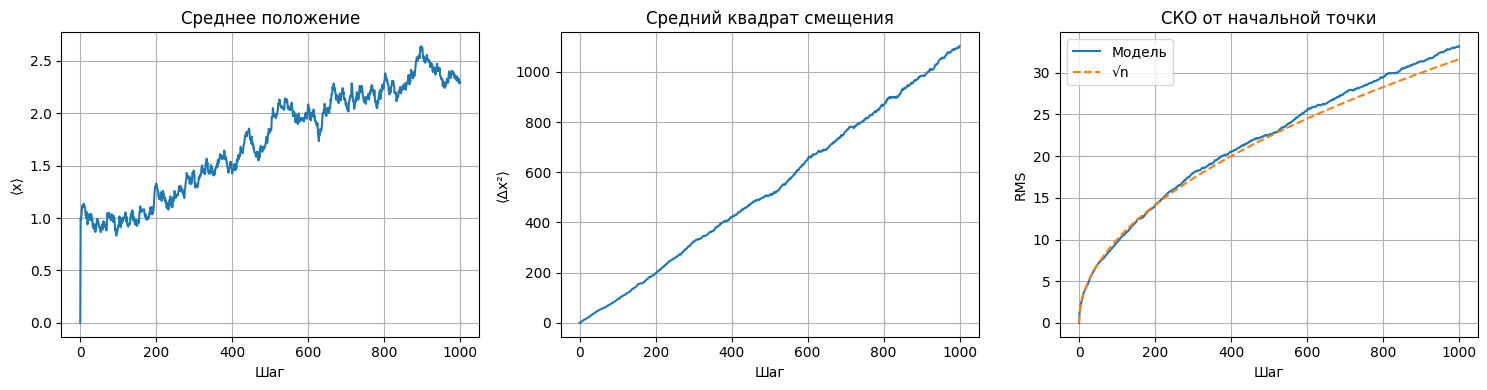

При фиксированном первом шаге +1 теоретическое среднее при n≥1 равно 1.


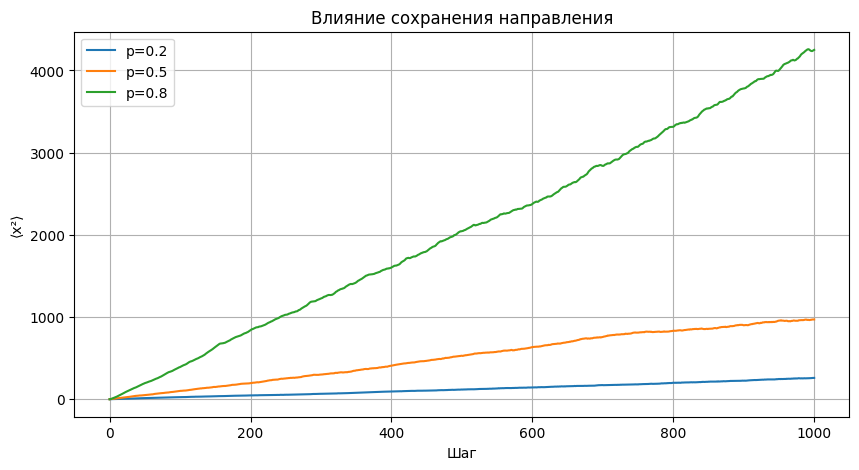

In [46]:
NStep,NTrial,p,x0,dx=1000,1000,.5,0,1
M=Walk2(NStep,NTrial,p,x0,dx)
steps=np.arange(NStep+1); mean=M.mean(axis=1)
fig,axes=plt.subplots(1,3,figsize=(15,4))
chart(axes[0],steps,mean,'Среднее положение','Шаг','⟨x⟩')
chart(axes[1],steps,np.mean((M-x0)**2,axis=1),'Средний квадрат смещения','Шаг','⟨Δx²⟩')
chart(axes[2],steps,np.sqrt(np.mean((M-x0)**2,axis=1)),'СКО от начальной точки','Шаг','RMS',label='Модель')
axes[2].plot(steps,np.sqrt(steps),'--',label='√n'); axes[2].legend()
plt.tight_layout(); plt.show()
print('При фиксированном первом шаге +1 теоретическое среднее при n≥1 равно 1.')
fig,ax=plt.subplots()
for prob in [.2,.5,.8]:
    X=Walk2(1000,1000,prob,0,1)
    chart(ax,steps,np.mean(X**2,axis=1),'Влияние сохранения направления','Шаг','⟨x²⟩',label=f'p={prob}')
ax.legend(); plt.show()

### Моделирование движения решеточного газа

В модели решеточного газа рассматривается случайное движение невзаимодействующих
друг с другом частиц (пешеходов) на двумерной или трехмерной решетках. В данной модели действует исключение: две частицы не могут занимать один узел. Это ограничение является взаимодействием; иных сил между частицами нет. (Данная модель используется в физике твердого тела, так как в твердых
телах (в первую очередь в металлах) диффузия обусловлена температурными
вакансиями, концентрация которых зависит от температуры.) Основной
характеристикой, представляющей интерес с физической точки зрения, в данной
задаче является коэффициент диффузии D. Метод Монте-Карло в данной задаче
реализуется в соответствии со следующим алгоритмом:
1. Задать числа узлов решетки $L$.
2. Задать число частиц $N$ ($N ≤ L^2$).
3. Задать начальное распределение частиц.
4. Перемещать частицы случайным образом в один из свободных соседних узлов.
(Если узел оказывается занятым, то частица остается в текущем узле.)

#### Задание. Создать функцию, возвращающую начальную конфигурацию системы

In [47]:
def InitL(L,NParticle):
    if not 0<NParticle<=L*L: raise ValueError('Недопустимое число частиц')
    sites=rng.choice(L*L,NParticle,replace=False)
    x,y=sites//L,sites%L
    Site=np.zeros((L,L),dtype=bool); Site[x,y]=True
    return x,y,Site

#### Задание. Создать функцию, возвращающую мгновенные (на каждом шаге Монте-Карло) значения координат частиц системы.

In [48]:
def MoveL(L,NParticle,NTrial,x,y,Site):
    # Периодические границы. Для диффузии сохраняем развёрнутые координаты.
    positions=np.column_stack((x,y)).astype(int).copy()
    occupied=Site.copy()
    C=np.empty((NTrial+1,NParticle,2),dtype=int); C[0]=positions
    directions=np.array([[1,0],[-1,0],[0,1],[0,-1]])
    for n in range(1,NTrial+1):
        for i in rng.permutation(NParticle):
            delta=directions[rng.integers(4)]
            old=positions[i]%L; new=(positions[i]+delta)%L
            if not occupied[tuple(new)]:
                occupied[tuple(old)]=False; occupied[tuple(new)]=True
                positions[i]+=delta
        C[n]=positions
        assert occupied.sum()==NParticle
    return C

#### Задание. Промоделируем с помощью функций

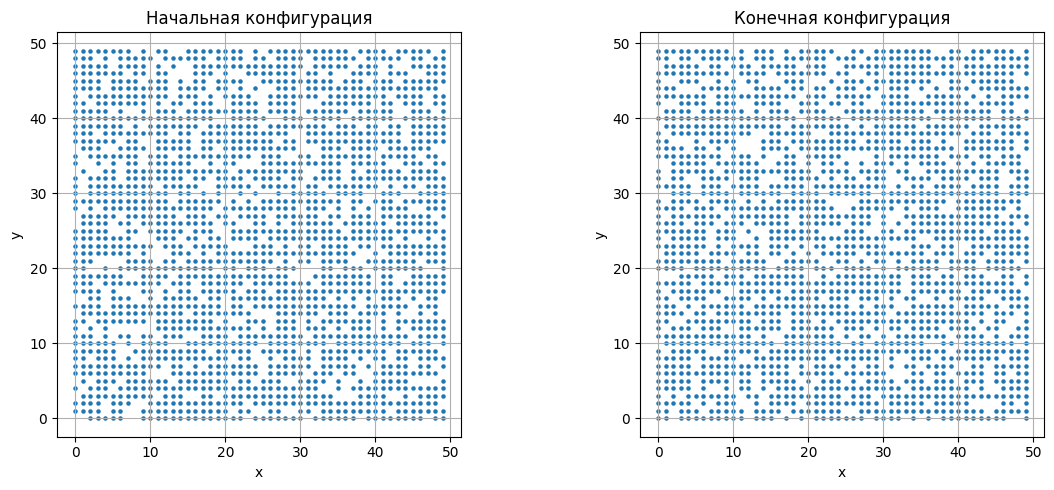

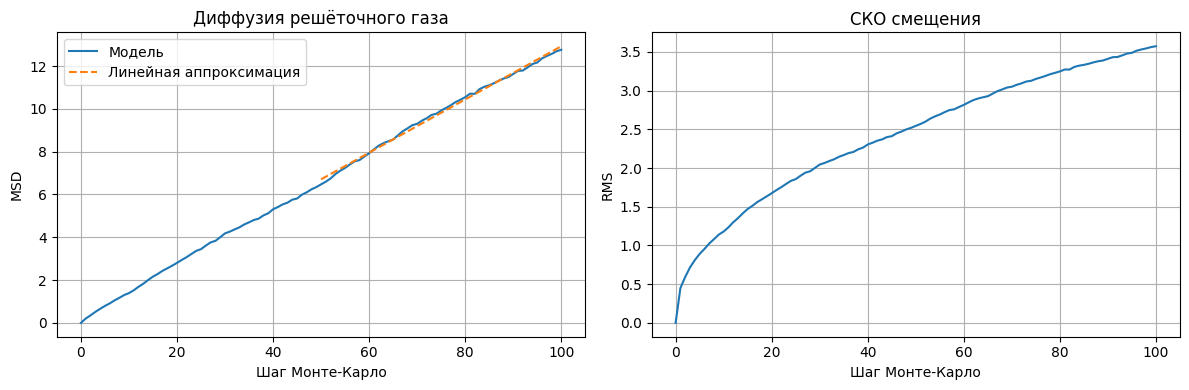

Заполнение: 80%; D ≈ 0.03109 узлов²/шаг
Оценка по второй половине одного прогона; свободная частица имеет D = 0.25.


In [49]:
L,NParticle,NTrial=50,2000,100
Xi,Yi,Site=InitL(L,NParticle)
C=MoveL(L,NParticle,NTrial,Xi,Yi,Site)
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,coords,title in [(axes[0],C[0],'Начальная конфигурация'),(axes[1],C[-1]%L,'Конечная конфигурация')]:
    ax.scatter(*coords.T,s=5); ax.set(title=title,xlabel='x',ylabel='y',aspect='equal')
plt.tight_layout(); plt.show()
steps=np.arange(NTrial+1)
msd=np.mean(np.sum((C-C[0])**2,axis=2),axis=1)
slope,intercept=np.polyfit(steps[50:],msd[50:],1)
D=slope/4
fig,axes=plt.subplots(1,2,figsize=(12,4))
chart(axes[0],steps,msd,'Диффузия решёточного газа','Шаг Монте-Карло','MSD',label='Модель')
axes[0].plot(steps[50:],slope*steps[50:]+intercept,'--',label='Линейная аппроксимация'); axes[0].legend()
chart(axes[1],steps,np.sqrt(msd),'СКО смещения','Шаг Монте-Карло','RMS')
plt.tight_layout(); plt.show()
print(f'Заполнение: {NParticle/L**2:.0%}; D ≈ {D:.5f} узлов²/шаг')
print('Оценка по второй половине одного прогона; свободная частица имеет D = 0.25.')
assert all(len(np.unique(coords%L,axis=0))==NParticle for coords in C)

In [50]:
# Десять проверок физических и численных свойств решения.
# 1. Однородное поле: сравнение координат с аналитическим решением.
assert np.max(np.abs(Rmag[:, :3]-exact)) < 1e-7
# 2. Сохранение энергии в однородном поле.
assert np.ptp(np.sum(Rmag[:,3:]**2,axis=1)) < 1e-8
# 3. Скрещённые поля: аналитическое классическое решение из покоя.
for e in [.01,.1,.4]:
    classical = em_results[(e,False)]
    analytical = np.column_stack((e*(te-np.sin(2*np.pi*te)/(2*np.pi)),
                                  e*(1-np.cos(2*np.pi*te))/(2*np.pi), np.zeros_like(te)))
    assert np.max(np.abs(classical[:,:3]-analytical)) < 1e-7
# 4. Релятивистская скорость меньше c; сохраняется γ−2π Ey y.
for e in [.01,.1,.4]:
    relativistic=em_results[(e,True)]
    v2=np.sum(relativistic[:,3:]**2,axis=1)
    assert np.all(v2<1)
    invariant=1/np.sqrt(1-v2)-2*np.pi*e*relativistic[:,1]
    assert np.max(np.abs(invariant-1)) < 1e-6
# 5. Диполь: конечность решения, отсутствие сингулярности, сохранение энергии.
for ss in [states,states_low]:
    assert np.isfinite(ss).all()
    energy=np.sum(ss[:,1::2]**2,axis=1)
    assert np.max(np.abs(energy-energy[0]))/energy[0] < 1e-5
    assert np.linalg.norm(ss[:,::2],axis=1).min() > 1e-3
assert np.isfinite(field([1.,0.,0.])).all()
# 6. Одномерное блуждание: допустимая решётка, нормировка и частоты χ².
assert np.all(np.abs(Mwalk) <= 1000) and np.all(Mwalk % 2 == 0)
assert np.isclose(probabilities.sum(),1.)
assert observed.sum()==len(Mwalk) and np.isclose(expected.sum(),len(Mwalk))
assert expected.min() >= 5
# 7. Начальные точки внутри круга; каждый плоский шаг имеет длину 1.
assert np.max(np.linalg.norm(A,axis=1)) <= 1
assert np.allclose(np.sum(np.diff(Am,axis=0)**2,axis=2),1)
# 8. Персистентное блуждание: первый шаг задан, остальные имеют ту же длину.
assert np.allclose(M[0],0) and np.allclose(M[1],1)
assert np.allclose(np.abs(np.diff(M,axis=0)),1)
# 9. Решёточный газ: нет совпадающих частиц и запрещённых скачков.
assert all(len(np.unique(coords%L,axis=0))==NParticle for coords in C)
assert np.all(np.sum(np.abs(np.diff(C,axis=0)),axis=2)<=1)
# 10. Полностью заполненная решётка неподвижна; пустое поле даёт прямую.
xx,yy,site=InitL(3,9)
full=MoveL(3,9,3,xx,yy,site)
assert np.all(full==full[0])
test_times=np.linspace(0,1,11)
free=integrate(lambda t,s:LorenzForce(t,s,(0,0,0)),[0,0,0,.1,.2,.3],test_times)
assert np.allclose(free[:,:3],test_times[:,None]*np.array([.1,.2,.3]))
print('Все 10 групп проверок пройдены.')

Все 10 групп проверок пройдены.


## Выводы по работе

Для одномерных независимых шагов среднее смещение равно N(2p−1), дисперсия — 4Np(1−p). При p=0.5 распределение симметрично, СКО растёт как √N. Статистическая проверка и её фактический результат приведены в расчёте.

На плоскости средний квадрат смещения растёт примерно линейно с числом шагов, а центр большого ансамбля остаётся близок к началу. Начальные точки равномерно распределены по площади круга благодаря радиусу R√u.

При персистентном блуждании увеличение вероятности сохранения направления усиливает распространение ансамбля. В алгоритме исходника неравенства противоречат определению p; в решении p означает именно вероятность сохранения направления.

В решёточном газе запрещено совместное занятие узла: это взаимодействие исключения, несмотря на формулировку о невзаимодействующих частицах. При заполнении 80% блокировка ходов замедляет диффузию. Один шаг Монте-Карло соответствует одной попытке перемещения каждой частицы в случайном порядке. Коэффициент D оценён из MSD ≈ 4Dt; периодические границы не искажают смещения, поскольку используются развёрнутые координаты.

Все случайные расчёты воспроизводимы при последовательном запуске ячеек благодаря фиксированному начальному состоянию генератора.